In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/Social_Network_Ads.csv')

In [3]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [4]:
df = df.iloc[:,2:]

In [5]:
df.sample(5)

,Age,EstimatedSalary,Purchased
35,35,27000,0
245,51,146000,1
216,49,65000,0
333,40,65000,0
18,46,28000,1


### X = Input Features ; y = Output

In [6]:
X = df.drop('Purchased',axis=1)
y = df['Purchased']

##Tain-Test split

In [7]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=0)

X_train.shape,X_test.shape

((280, 2), (120, 2))

##StandardScaler in scikitlearn(sklear.preprocessing import StandardScalar

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() #ojectcreation for model

#Fit scaler to the train set ,it will laern the parameters
scaler.fit(X_train) # fit means 'getting column values' and calculating 'mean' and 'Standard deviation"of both columns 'from X_train' and Fitting it to the object 'scalar'
#Passing column

#transform train and test sets
X_train_scaled = scaler.transform(X_train) #taking each point from X_train and transforming
X_test_scaled = scaler.transform(X_test)



In [9]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [10]:
X_train_scaled

array([[-1.1631724 , -1.5849703 ],
       [ 2.17018137,  0.93098672],
       [ 0.0133054 ,  1.22017719],
       [ 0.20938504,  1.07558195],
       [ 0.40546467, -0.48604654],
       [-0.28081405, -0.31253226],
       [ 0.99370357, -0.8330751 ],
       [ 0.99370357,  1.8563962 ],
       [ 0.0133054 ,  1.24909623],
       [-0.86905295,  2.26126285],
       [-1.1631724 , -1.5849703 ],
       [ 2.17018137, -0.80415605],
       [-1.35925203, -1.46929411],
       [ 0.40546467,  2.2901819 ],
       [ 0.79762394,  0.75747245],
       [-0.96709276, -0.31253226],
       [ 0.11134522,  0.75747245],
       [-0.96709276,  0.55503912],
       [ 0.30742485,  0.06341534],
       [ 0.69958412, -1.26686079],
       [-0.47689368, -0.0233418 ],
       [-1.7514113 ,  0.3526058 ],
       [-0.67297331,  0.12125343],
       [ 0.40546467,  0.29476771],
       [-0.28081405,  0.06341534],
       [-0.47689368,  2.2901819 ],
       [ 0.20938504,  0.03449629],
       [ 1.28782302,  2.20342476],
       [ 0.79762394,

In [11]:
#StandardScaler returns a numpy array and so :
## we convert 'X_trained scaled to Dataframe:
X_train_scaled = pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled,columns = X_test.columns)

In [12]:
X_train_scaled

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


In [13]:
np.round(X_train.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [14]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


##Effect Of Scaling

#This line of code uses Matplotlib to create a figure containing **two side-by-side plots** so you can easily compare your data before and after scaling.

*(Note: There is a small syntax typo in the line—it is missing an `=` sign after `figsize`. It should be `figsize=(12,5)` instead of `figsize(12,5)`.)*

Here is what each part of the line does:

* **`plt.subplots(...)`**: This function sets up the overall canvas and the individual plot areas inside it.
* **`ncols=2`**: Tells Matplotlib to arrange the plots into **2 columns** (side-by-side) in a single row.
* **`figsize=(12, 5)`**: Sets the overall size of the entire figure canvas in inches—**12 inches wide** by **5 inches tall**.
* **`fig, (ax1, ax2) = ...`**: Unpacks the two things that `plt.subplots()` creates:
* **`fig`**: The overall outer container/window holding everything.
* **`(ax1, ax2)`**: The two individual subplot axes inside that container. In your notebook, `ax1` is used on the left for the `"Before Scaling"` scatter plot, and `ax2` is used on the right for the `"After Scaling"` scatter plot.



**Corrected code for your cell:**

```python
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

```

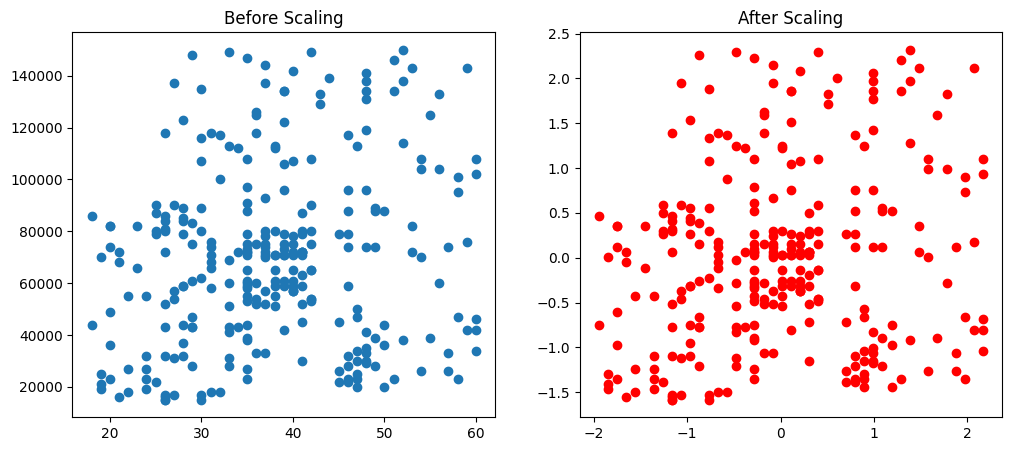

In [15]:
fig,(ax1,ax2)= plt.subplots(ncols=2,figsize=(12,5))
ax1.scatter(x=X_train['Age'],y=X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'],X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("After Scaling")
plt.show()

PDF - After scaling both features become comparable

<Axes: xlabel='Age', ylabel='Density'>

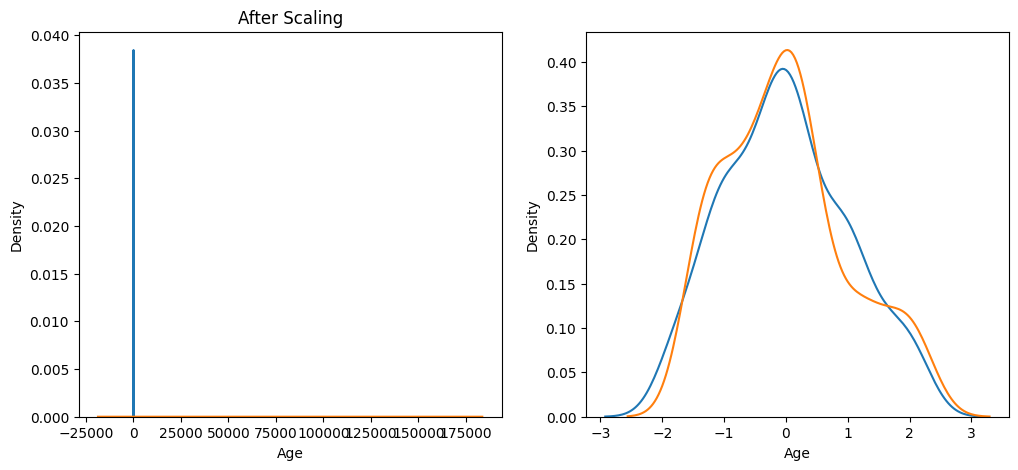

In [16]:
fig,(ax1,ax2)= plt.subplots(ncols=2,figsize=(12,5))

#before scaling
ax1.set_title("Before Scaling")
sns.kdeplot(X_train['Age'],ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'],ax=ax1)

#after scaling
ax1.set_title("After Scaling")
sns.kdeplot(X_train_scaled['Age'],ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'],ax=ax2)

##Comparison of Distributions

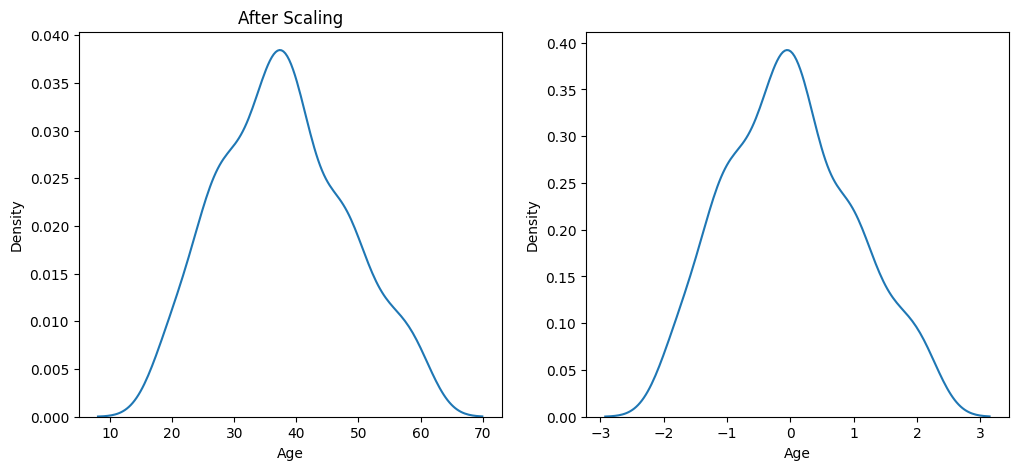

In [17]:
fig,(ax1,ax2)= plt.subplots(ncols=2,figsize=(12,5))

#before scaling
ax1.set_title("Before Scaling")
sns.kdeplot(X_train['Age'],ax=ax1)


#after scaling
ax1.set_title("After Scaling")
sns.kdeplot(X_train_scaled['Age'],ax=ax2)
plt.show()

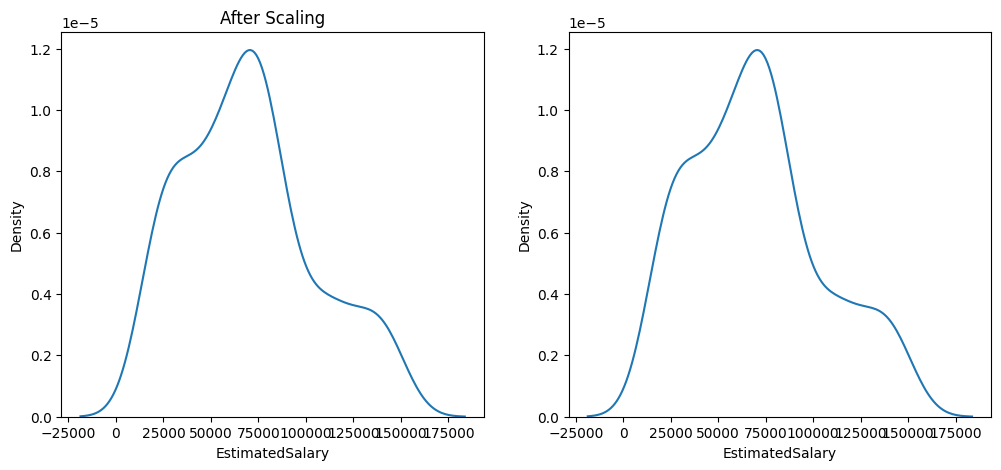

In [18]:
fig,(ax1,ax2)= plt.subplots(ncols=2,figsize=(12,5))

#before scaling
ax1.set_title("Before Scaling")
sns.kdeplot(X_train['EstimatedSalary'],ax=ax1)

#after scaling
ax1.set_title("After Scaling")
sns.kdeplot(X_train['EstimatedSalary'],ax=ax2)
plt.show()

#The shape of distribution reamins same... only the mean =0 and std deviation =1

#Why scaling is important

In [19]:
from sklearn.linear_model import LogisticRegression

In [20]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [21]:
lr.fit(X_train,y_train)
lr_scaled.fit(X_train_scaled,y_train)

LogisticRegression()

In [22]:
y_pred= lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [23]:
from sklearn.metrics import accuracy_score

In [24]:
print("Actual",accuracy_score(y_test,y_pred))
print("Scaled",accuracy_score(y_test,y_pred_scaled))

Actual 0.875
Scaled 0.8666666666666667


In your notebook, the unscaled model got **87.5%** (`0.875`) accuracy while the scaled model got **86.7%** (`0.8667`)—a tiny difference of just **1 single test sample** out of 120 (`105/120` vs. `104/120`).

Here is why that happens here:

1. **L2 Regularization Penalty (`C=1.0`)**: Scikit-learn's `LogisticRegression` applies L2 regularization by default. Before scaling, `EstimatedSalary` is on a massive scale (up to 150,000) compared to `Age` (up to 60), so the model assigns a tiny weight to `EstimatedSalary` that barely gets penalized by L2 regularization. After `StandardScaler`, both features are on the same scale (`std = 1`), so regularization penalizes both weights equally, shifting the decision boundary slightly and flipping 1 borderline test prediction.
2. **Small Test Set Size**: Because `X_test` only has **120 rows**, a single prediction flipping changes the accuracy by `1 / 120 = 0.83%`.

**When scaling actually shines:**

* Even though accuracy is nearly identical here, scaling is still best practice for Logistic Regression because it ensures **faster, more reliable solver convergence** (especially on larger datasets where unscaled features trigger `ConvergenceWarning`).
* You will see a **massive jump in accuracy after scaling** if you test distance-based algorithms like **K-Nearest Neighbors (KNN)** or **Support Vector Machines (SVM)** on this same `Social_Network_Ads` dataset, where unscaled `EstimatedSalary` completely dominates distance calculations.

In [25]:
from sklearn.tree import DecisionTreeClassifier

In [26]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

In [27]:
dt.fit(X_train,y_train)
dt_scaled.fit(X_train_scaled,y_train)

DecisionTreeClassifier()

In [28]:
y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

In [29]:
from sklearn.metrics import accuracy_score

In [30]:
print("Actual",accuracy_score(y_test,y_pred))
print("Scaled",accuracy_score(y_test,y_pred_scaled))

Actual 0.875
Scaled 0.875


In [31]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


There are two issues in that line of code:

1. **Deprecated method (`AttributeError`)**: `df.append()` was completely removed in **pandas 2.0** (which Google Colab uses). Use `pd.concat()` instead.


2. **Array length mismatch (`ValueError`)**: In your dictionary, `'Age'` only has **2 values** (`[5, 90.95]`), while `'EstimatedSalary'` (`[1000, 250000, 350000]`) and `'Purchased'` (`[0, 1, 1]`) each have **3 values**. Every column list must have the exact same number of items (you likely meant `[5, 90, 95]` with a comma instead of a decimal point `90.95`).



**Corrected code:**

```python
new_rows = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})

df = pd.concat([df, new_rows], ignore_index=True)

```

##Effect of Outlier

In [32]:
df = pd.concat([df,pd.DataFrame({'Age':[5,90,95],'EstimatedSalary' : [1000,250000,350000],'Purchased':[0,1,1]})],ignore_index=True)

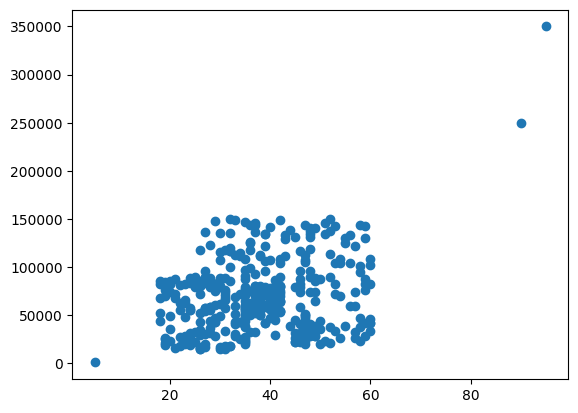

In [33]:
plt.scatter(x=df['Age'],y=df['EstimatedSalary'])

In [34]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),df['Purchased'],test_size=0.3,random_state=0)

X_train.shape, X_test.shape

((282, 2), (121, 2))

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [36]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

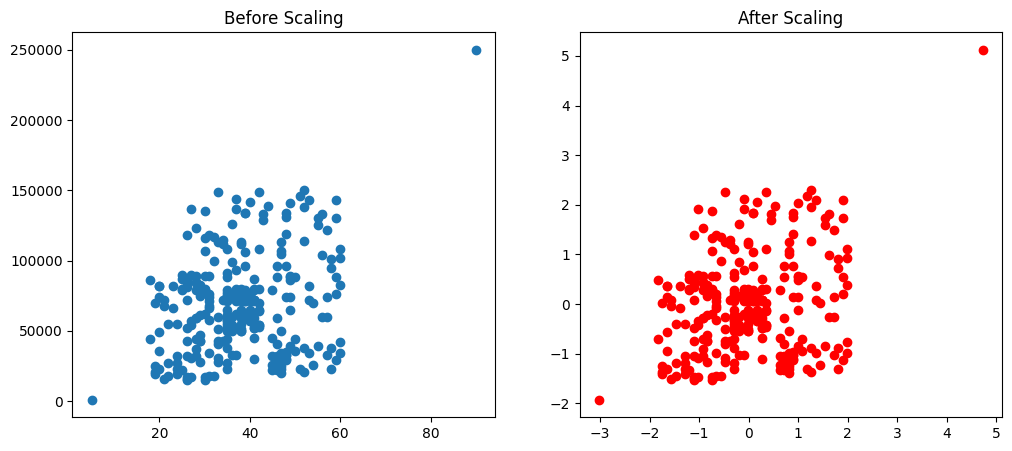

In [37]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("After Scaling")
plt.show()